# Predicting Myocardial Infarction Risk
## Supervised Machine Learning

**Project No.: 49**  
**Course: Machine Learning**


## Objective

To develop supervised machine learning models for predicting myocardial infarction risk using the given dataset.

In [3]:
import pandas as pd

# Load the dataset
df = pd.read_csv('/content/heart.csv')

# Display basic information
print("Dataset Shape:", df.shape)

print("\nFirst 5 rows:")
display(df.head())

print("\nColumn Names:")
print(df.columns.tolist())

print("\nDataset Information:")
df.info()

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Rows:", df.duplicated().sum())

print("\nTarget Distribution:")
print(df['output'].value_counts())

Dataset Shape: (303, 14)

First 5 rows:


,age,sex,cp,trtbps,chol,fbs,restecg,thalachh,exng,oldpeak,slp,caa,thall,output
0,63,1,3,145,233,1,0,150,0,2.3,0,0,1,1
1,37,1,2,130,250,0,1,187,0,3.5,0,0,2,1
2,41,0,1,130,204,0,0,172,0,1.4,2,0,2,1
3,56,1,1,120,236,0,1,178,0,0.8,2,0,2,1
4,57,0,0,120,354,0,1,163,1,0.6,2,0,2,1



Column Names:
['age', 'sex', 'cp', 'trtbps', 'chol', 'fbs', 'restecg', 'thalachh', 'exng', 'oldpeak', 'slp', 'caa', 'thall', 'output']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 303 entries, 0 to 302
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       303 non-null    int64  
 1   sex       303 non-null    int64  
 2   cp        303 non-null    int64  
 3   trtbps    303 non-null    int64  
 4   chol      303 non-null    int64  
 5   fbs       303 non-null    int64  
 6   restecg   303 non-null    int64  
 7   thalachh  303 non-null    int64  
 8   exng      303 non-null    int64  
 9   oldpeak   303 non-null    float64
 10  slp       303 non-null    int64  
 11  caa       303 non-null    int64  
 12  thall     303 non-null    int64  
 13  output    303 non-null    int64  
dtypes: float64(1), int64(13)
memory usage: 33.3 KB

Missing Values:
age         0
sex         0
cp          0
tr

In [4]:
# Inspect duplicate records
duplicate_rows = df[df.duplicated(keep=False)]

print("Duplicate records found:", len(duplicate_rows))
display(duplicate_rows)

Duplicate records found: 2


,age,sex,cp,trtbps,chol,fbs,restecg,thalachh,exng,oldpeak,slp,caa,thall,output
163,38,1,2,138,175,0,1,173,0,0.0,2,4,2,1
164,38,1,2,138,175,0,1,173,0,0.0,2,4,2,1


## Data Quality Check

Before preprocessing and model training, duplicate records are examined to determine whether they should be removed.


## Data Cleaning

The dataset contains one exact duplicate record. Since both occurrences contain identical values across all features and the target, one copy is removed to avoid giving the same observation additional influence during model training.

In [5]:
# Remove exact duplicate records
df = df.drop_duplicates().reset_index(drop=True)

print("Dataset shape after removing duplicates:", df.shape)
print("Remaining duplicate rows:", df.duplicated().sum())

Dataset shape after removing duplicates: (302, 14)
Remaining duplicate rows: 0


## Exploratory Data Analysis

Descriptive statistics are examined to understand the distribution and range of the dataset features before model development.

In [6]:
# Descriptive statistics of the cleaned dataset
display(df.describe().T)

,count,mean,std,min,25%,50%,75%,max
age,302.0,54.420530,9.047970,29.0,48.00,55.5,61.00,77.0
sex,302.0,0.682119,0.466426,0.0,0.00,1.0,1.00,1.0
cp,302.0,0.963576,1.032044,0.0,0.00,1.0,2.00,3.0
trtbps,302.0,131.602649,17.563394,94.0,120.00,130.0,140.00,200.0
chol,302.0,246.500000,51.753489,126.0,211.00,240.5,274.75,564.0
fbs,302.0,0.149007,0.356686,0.0,0.00,0.0,0.00,1.0
restecg,302.0,0.526490,0.526027,0.0,0.00,1.0,1.00,2.0
thalachh,302.0,149.569536,22.903527,71.0,133.25,152.5,166.00,202.0
exng,302.0,0.327815,0.470196,0.0,0.00,0.0,1.00,1.0
oldpeak,302.0,1.043046,1.161452,0.0,0.00,0.8,1.60,6.2


## Target Variable Distribution

The distribution of the target variable is visualized to examine the balance between the two outcome classes.

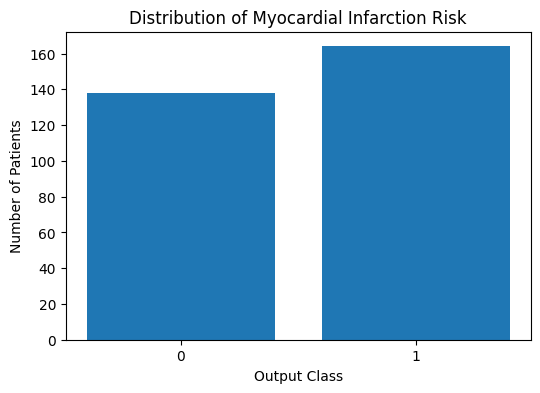

Target distribution:
output
0    138
1    164
Name: count, dtype: int64


In [7]:
import matplotlib.pyplot as plt

# Target class distribution
target_counts = df['output'].value_counts().sort_index()

plt.figure(figsize=(6, 4))
plt.bar(['0', '1'], target_counts.values)
plt.xlabel('Output Class')
plt.ylabel('Number of Patients')
plt.title('Distribution of Myocardial Infarction Risk')
plt.show()

print("Target distribution:")
print(target_counts)

## Distribution of Continuous Features

The distributions of the main continuous features are visualized to understand their ranges and identify potential differences in their distributions before model development.

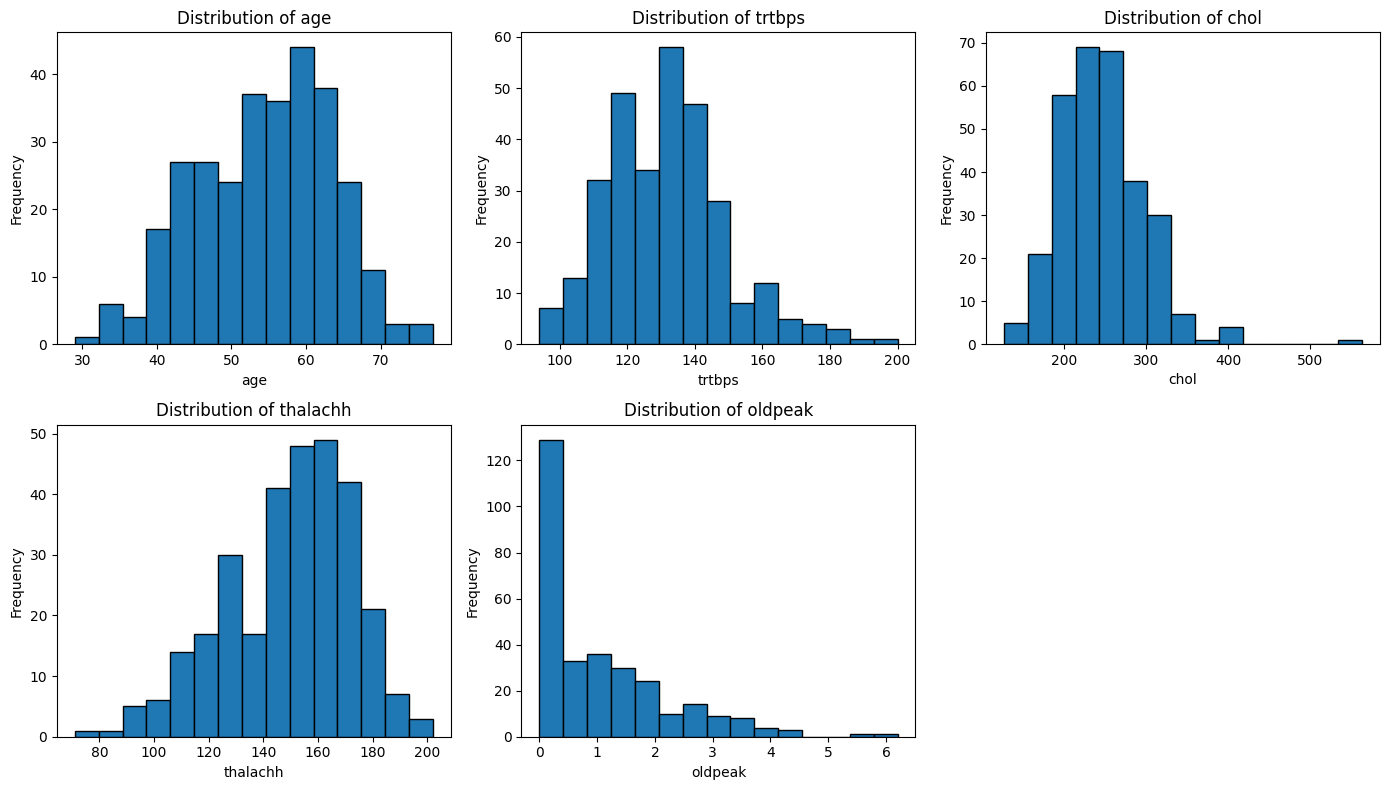

In [8]:
# Visualize distributions of continuous features

continuous_features = ['age', 'trtbps', 'chol', 'thalachh', 'oldpeak']

fig, axes = plt.subplots(2, 3, figsize=(14, 8))
axes = axes.flatten()

for i, feature in enumerate(continuous_features):
    axes[i].hist(df[feature], bins=15, edgecolor='black')
    axes[i].set_title(f'Distribution of {feature}')
    axes[i].set_xlabel(feature)
    axes[i].set_ylabel('Frequency')

# Hide unused subplot
axes[-1].axis('off')

plt.tight_layout()
plt.show()

## Correlation Analysis

A correlation matrix is used to examine the linear relationships among the dataset variables and to identify potentially related features.

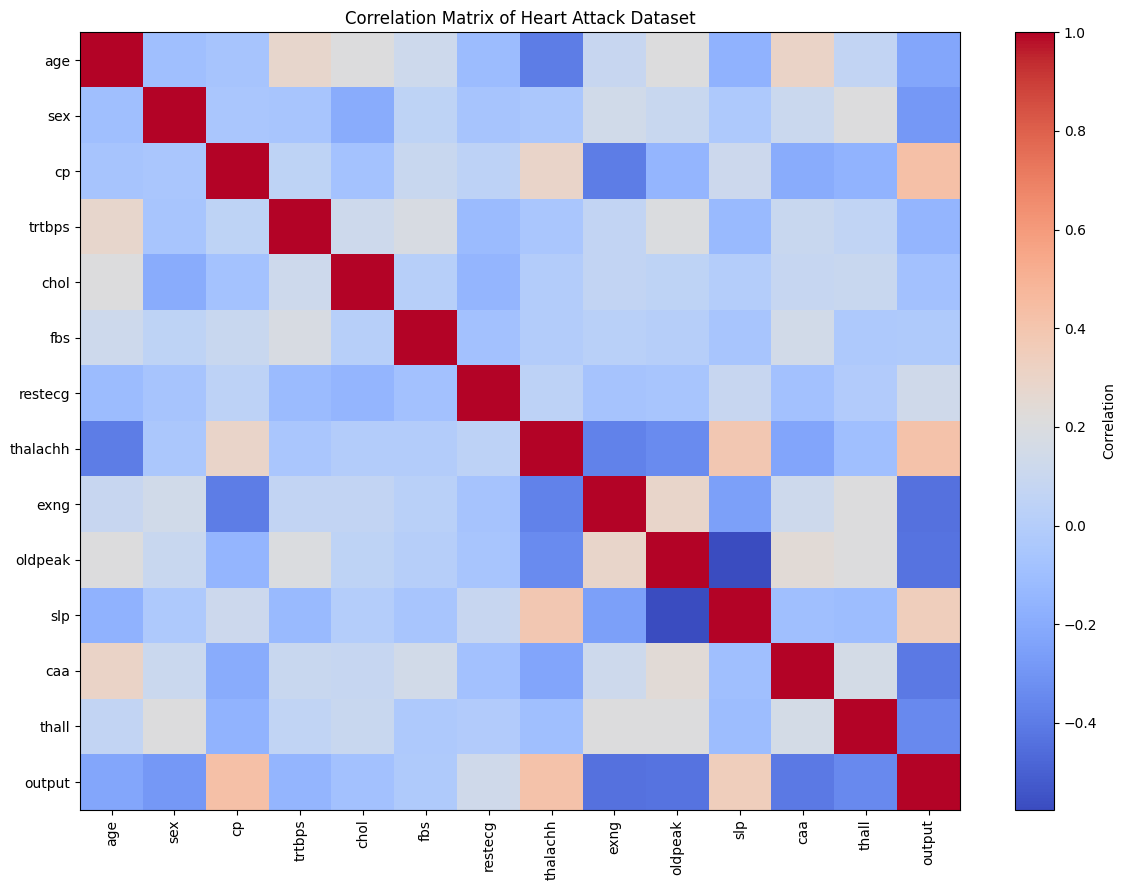

In [9]:
# Correlation matrix
correlation_matrix = df.corr()

plt.figure(figsize=(12, 9))
plt.imshow(correlation_matrix, cmap='coolwarm', aspect='auto')
plt.colorbar(label='Correlation')

plt.xticks(
    range(len(correlation_matrix.columns)),
    correlation_matrix.columns,
    rotation=90
)

plt.yticks(
    range(len(correlation_matrix.columns)),
    correlation_matrix.columns
)

plt.title('Correlation Matrix of Heart Attack Dataset')
plt.tight_layout()
plt.show()

## Distribution of Categorical Features

The distributions of the categorical and discrete features are visualized to understand the representation of their respective categories in the dataset.

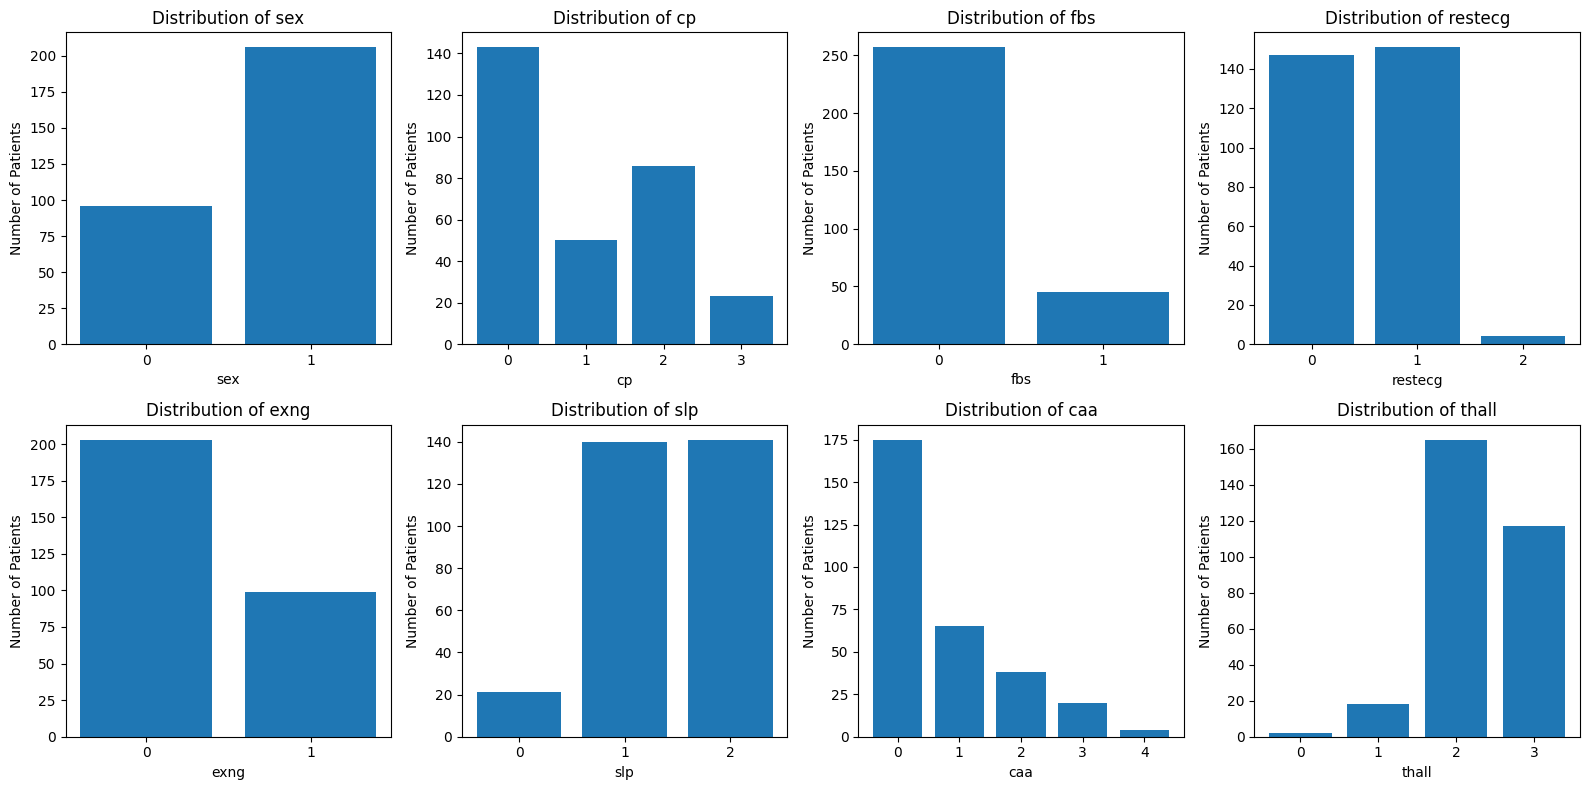

In [10]:
# Visualize categorical/discrete feature distributions

categorical_features = [
    'sex', 'cp', 'fbs', 'restecg',
    'exng', 'slp', 'caa', 'thall'
]

fig, axes = plt.subplots(2, 4, figsize=(16, 8))
axes = axes.flatten()

for i, feature in enumerate(categorical_features):
    counts = df[feature].value_counts().sort_index()

    axes[i].bar(counts.index.astype(str), counts.values)
    axes[i].set_title(f'Distribution of {feature}')
    axes[i].set_xlabel(feature)
    axes[i].set_ylabel('Number of Patients')

plt.tight_layout()
plt.show()

## Feature Distribution by Target Class

The distributions of continuous clinical features are compared across the two outcome classes to examine how the features vary with the target.

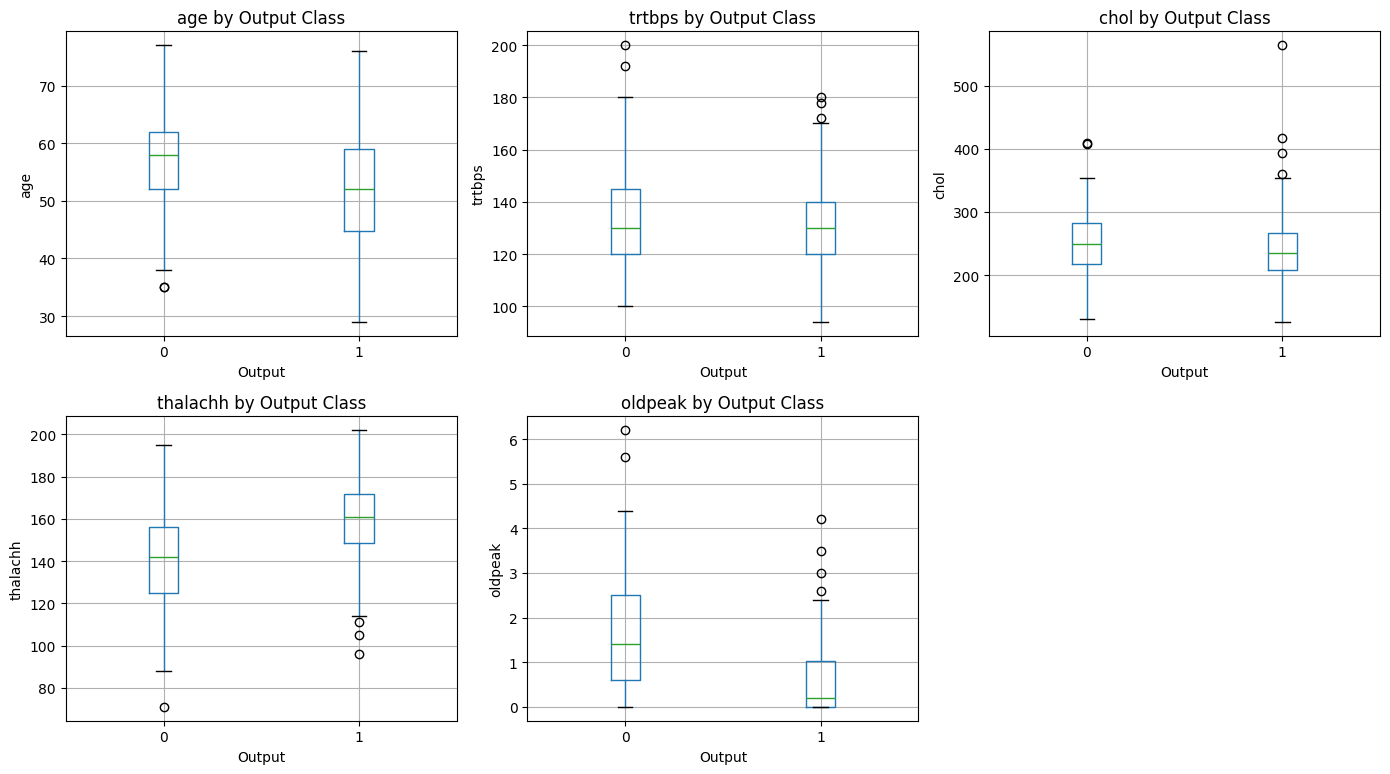

In [11]:
# Compare continuous features across target classes

continuous_features = ['age', 'trtbps', 'chol', 'thalachh', 'oldpeak']

fig, axes = plt.subplots(2, 3, figsize=(14, 8))
axes = axes.flatten()

for i, feature in enumerate(continuous_features):
    df.boxplot(column=feature, by='output', ax=axes[i])
    axes[i].set_title(f'{feature} by Output Class')
    axes[i].set_xlabel('Output')
    axes[i].set_ylabel(feature)

# Remove automatic pandas figure title
plt.suptitle('')

# Hide unused subplot
axes[-1].axis('off')

plt.tight_layout()
plt.show()

## Feature and Target Separation

The predictor variables are separated from the target variable (`output`) before preparing the data for supervised learning.

In [12]:
# Separate features and target
X = df.drop('output', axis=1)
y = df['output']

print("Feature matrix shape:", X.shape)
print("Target shape:", y.shape)
print("Features:", X.columns.tolist())

Feature matrix shape: (302, 13)
Target shape: (302,)
Features: ['age', 'sex', 'cp', 'trtbps', 'chol', 'fbs', 'restecg', 'thalachh', 'exng', 'oldpeak', 'slp', 'caa', 'thall']


## Train, Validation and Test Split

The cleaned dataset is divided into training, validation, and test sets using a stratified split. Stratification preserves the target-class distribution across the three subsets.

In [13]:
from sklearn.model_selection import train_test_split

# First split: 60% training, 40% temporary
X_train, X_temp, y_train, y_temp = train_test_split(
    X,
    y,
    test_size=0.40,
    stratify=y,
    random_state=42
)

# Second split: divide the temporary set equally into validation and test
X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    stratify=y_temp,
    random_state=42
)

print("Training set:", X_train.shape, y_train.shape)
print("Validation set:", X_val.shape, y_val.shape)
print("Test set:", X_test.shape, y_test.shape)

print("\nTarget distribution:")
print("Train:\n", y_train.value_counts(normalize=True).sort_index())
print("Validation:\n", y_val.value_counts(normalize=True).sort_index())
print("Test:\n", y_test.value_counts(normalize=True).sort_index())

Training set: (181, 13) (181,)
Validation set: (60, 13) (60,)
Test set: (61, 13) (61,)

Target distribution:
Train:
 output
0    0.458564
1    0.541436
Name: proportion, dtype: float64
Validation:
 output
0    0.45
1    0.55
Name: proportion, dtype: float64
Test:
 output
0    0.459016
1    0.540984
Name: proportion, dtype: float64


In [14]:
# Verify there is no overlap between the three datasets
print("Train/Validation overlap:", len(set(X_train.index) & set(X_val.index)))
print("Train/Test overlap:", len(set(X_train.index) & set(X_test.index)))
print("Validation/Test overlap:", len(set(X_val.index) & set(X_test.index)))

Train/Validation overlap: 0
Train/Test overlap: 0
Validation/Test overlap: 0


## Feature Preprocessing

Continuous features are standardized because they have different numerical ranges. Categorical and discrete features are one-hot encoded so that their numerical category labels are not interpreted as ordered continuous values. The preprocessing transformations are fitted only on the training data to prevent data leakage.

In [15]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# Continuous numerical features
continuous_features = [
    'age',
    'trtbps',
    'chol',
    'thalachh',
    'oldpeak'
]

# Categorical/discrete features
categorical_features = [
    'sex',
    'cp',
    'fbs',
    'restecg',
    'exng',
    'slp',
    'caa',
    'thall'
]

# Preprocessing pipeline
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), continuous_features),
        ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False),
         categorical_features)
    ]
)

print("Continuous features:", continuous_features)
print("Categorical features:", categorical_features)

Continuous features: ['age', 'trtbps', 'chol', 'thalachh', 'oldpeak']
Categorical features: ['sex', 'cp', 'fbs', 'restecg', 'exng', 'slp', 'caa', 'thall']


In [16]:
# Fit preprocessing only on the training data
X_train_processed = preprocessor.fit_transform(X_train)

# Apply the already-fitted preprocessing to validation and test data
X_val_processed = preprocessor.transform(X_val)
X_test_processed = preprocessor.transform(X_test)

print("Processed training shape:", X_train_processed.shape)
print("Processed validation shape:", X_val_processed.shape)
print("Processed test shape:", X_test_processed.shape)

Processed training shape: (181, 30)
Processed validation shape: (60, 30)
Processed test shape: (61, 30)


## Logistic Regression Baseline

Logistic Regression is used as the first supervised classification model to establish an interpretable baseline for predicting myocardial infarction risk.

In [17]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

# Train Logistic Regression
logistic_model = LogisticRegression(
    max_iter=2000,
    random_state=42
)

logistic_model.fit(X_train_processed, y_train)

# Validation predictions
y_val_pred = logistic_model.predict(X_val_processed)
y_val_prob = logistic_model.predict_proba(X_val_processed)[:, 1]

# Validation metrics
logistic_results = {
    'Model': 'Logistic Regression',
    'Accuracy': accuracy_score(y_val, y_val_pred),
    'Precision': precision_score(y_val, y_val_pred),
    'Recall': recall_score(y_val, y_val_pred),
    'F1 Score': f1_score(y_val, y_val_pred),
    'ROC-AUC': roc_auc_score(y_val, y_val_prob)
}

print("Logistic Regression - Validation Results")
for metric, value in logistic_results.items():
    if metric != 'Model':
        print(f"{metric}: {value:.4f}")

Logistic Regression - Validation Results
Accuracy: 0.8333
Precision: 0.7949
Recall: 0.9394
F1 Score: 0.8611
ROC-AUC: 0.8810


In [18]:
# Store validation results for all supervised models

results = [logistic_results]

def evaluate_model(model, model_name):
    model.fit(X_train_processed, y_train)

    y_pred = model.predict(X_val_processed)
    y_prob = model.predict_proba(X_val_processed)[:, 1]

    result = {
        'Model': model_name,
        'Accuracy': accuracy_score(y_val, y_pred),
        'Precision': precision_score(y_val, y_pred),
        'Recall': recall_score(y_val, y_pred),
        'F1 Score': f1_score(y_val, y_pred),
        'ROC-AUC': roc_auc_score(y_val, y_prob)
    }

    results.append(result)

    print(f"\n{model_name} - Validation Results")
    for metric, value in result.items():
        if metric != 'Model':
            print(f"{metric}: {value:.4f}")

    return model

## Elastic Net Logistic Regression

Elastic Net Logistic Regression is evaluated to introduce combined L1 and L2 regularization and compare its performance with the standard Logistic Regression baseline.

In [19]:
from sklearn.linear_model import LogisticRegression

elastic_net_model = evaluate_model(
    LogisticRegression(
        penalty='elasticnet',
        solver='saga',
        l1_ratio=0.5,
        C=1.0,
        max_iter=5000,
        random_state=42
    ),
    'Elastic Net Logistic Regression'
)


Elastic Net Logistic Regression - Validation Results
Accuracy: 0.8167
Precision: 0.7750
Recall: 0.9394
F1 Score: 0.8493
ROC-AUC: 0.8833


## Ensemble Learning Models

Gradient Boosting and Bagging classifiers are evaluated to compare ensemble-based approaches with the linear classification models.

In [20]:
from sklearn.ensemble import GradientBoostingClassifier, BaggingClassifier
from sklearn.tree import DecisionTreeClassifier

# Gradient Boosting
gradient_boosting_model = evaluate_model(
    GradientBoostingClassifier(
        random_state=42
    ),
    'Gradient Boosting'
)

# Bagging
bagging_model = evaluate_model(
    BaggingClassifier(
        estimator=DecisionTreeClassifier(random_state=42),
        n_estimators=100,
        random_state=42
    ),
    'Bagging'
)


Gradient Boosting - Validation Results
Accuracy: 0.7833
Precision: 0.7778
Recall: 0.8485
F1 Score: 0.8116
ROC-AUC: 0.8238

Bagging - Validation Results
Accuracy: 0.8000
Precision: 0.7561
Recall: 0.9394
F1 Score: 0.8378
ROC-AUC: 0.8423


## Random Forest

Random Forest is evaluated as a tree-based ensemble classifier using multiple decision trees to improve predictive robustness.

In [21]:
from sklearn.ensemble import RandomForestClassifier

random_forest_model = evaluate_model(
    RandomForestClassifier(
        n_estimators=200,
        random_state=42
    ),
    'Random Forest'
)


Random Forest - Validation Results
Accuracy: 0.7833
Precision: 0.7381
Recall: 0.9394
F1 Score: 0.8267
ROC-AUC: 0.8474


## Support Vector Machine Models

Three Support Vector Machine kernels are evaluated: Linear, Radial Basis Function (RBF), and Polynomial. This allows comparison of linear and nonlinear decision boundaries for the classification task.

In [22]:
from sklearn.svm import SVC

# Linear SVM
svm_linear_model = evaluate_model(
    SVC(
        kernel='linear',
        probability=True,
        random_state=42
    ),
    'SVM - Linear'
)

# RBF SVM
svm_rbf_model = evaluate_model(
    SVC(
        kernel='rbf',
        probability=True,
        random_state=42
    ),
    'SVM - RBF'
)

# Polynomial SVM
svm_poly_model = evaluate_model(
    SVC(
        kernel='poly',
        degree=3,
        probability=True,
        random_state=42
    ),
    'SVM - Polynomial'
)


SVM - Linear - Validation Results
Accuracy: 0.7833
Precision: 0.7381
Recall: 0.9394
F1 Score: 0.8267
ROC-AUC: 0.9024

SVM - RBF - Validation Results
Accuracy: 0.8000
Precision: 0.7838
Recall: 0.8788
F1 Score: 0.8286
ROC-AUC: 0.8765

SVM - Polynomial - Validation Results
Accuracy: 0.7833
Precision: 0.7778
Recall: 0.8485
F1 Score: 0.8116
ROC-AUC: 0.8608


## Validation Performance Comparison

The validation performance of all supervised learning models is compared using accuracy, precision, recall, F1-score, and ROC-AUC.

In [23]:
import pandas as pd

results_df = pd.DataFrame(results)

display(
    results_df.style.format({
        'Accuracy': '{:.4f}',
        'Precision': '{:.4f}',
        'Recall': '{:.4f}',
        'F1 Score': '{:.4f}',
        'ROC-AUC': '{:.4f}'
    })
)

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Logistic Regression,0.8333,0.7949,0.9394,0.8611,0.8810
1,Elastic Net Logistic Regression,0.8167,0.7750,0.9394,0.8493,0.8833
2,Gradient Boosting,0.7833,0.7778,0.8485,0.8116,0.8238
3,Bagging,0.8000,0.7561,0.9394,0.8378,0.8423
4,Random Forest,0.7833,0.7381,0.9394,0.8267,0.8474
5,SVM - Linear,0.7833,0.7381,0.9394,0.8267,0.9024
6,SVM - RBF,0.8000,0.7838,0.8788,0.8286,0.8765
7,SVM - Polynomial,0.7833,0.7778,0.8485,0.8116,0.8608


## Neural Network

A Multilayer Perceptron (MLP) neural network is evaluated to capture potentially nonlinear relationships between the clinical features and the target variable.

In [24]:
from sklearn.neural_network import MLPClassifier

neural_network_model = evaluate_model(
    MLPClassifier(
        hidden_layer_sizes=(32, 16),
        activation='relu',
        solver='adam',
        alpha=0.0001,
        learning_rate_init=0.001,
        max_iter=2000,
        random_state=42
    ),
    'Neural Network'
)


Neural Network - Validation Results
Accuracy: 0.8333
Precision: 0.8108
Recall: 0.9091
F1 Score: 0.8571
ROC-AUC: 0.8272


In [25]:
# Updated validation comparison including the Neural Network

results_df = pd.DataFrame(results)

display(
    results_df.style.format({
        'Accuracy': '{:.4f}',
        'Precision': '{:.4f}',
        'Recall': '{:.4f}',
        'F1 Score': '{:.4f}',
        'ROC-AUC': '{:.4f}'
    })
)

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Logistic Regression,0.8333,0.7949,0.9394,0.8611,0.8810
1,Elastic Net Logistic Regression,0.8167,0.7750,0.9394,0.8493,0.8833
2,Gradient Boosting,0.7833,0.7778,0.8485,0.8116,0.8238
3,Bagging,0.8000,0.7561,0.9394,0.8378,0.8423
4,Random Forest,0.7833,0.7381,0.9394,0.8267,0.8474
5,SVM - Linear,0.7833,0.7381,0.9394,0.8267,0.9024
6,SVM - RBF,0.8000,0.7838,0.8788,0.8286,0.8765
7,SVM - Polynomial,0.7833,0.7778,0.8485,0.8116,0.8608
8,Neural Network,0.8333,0.8108,0.9091,0.8571,0.8272


## Validation Model Performance Comparison

The validation performance of the supervised models is visualized using Accuracy, F1-score, and ROC-AUC to facilitate comparison across different classification approaches.

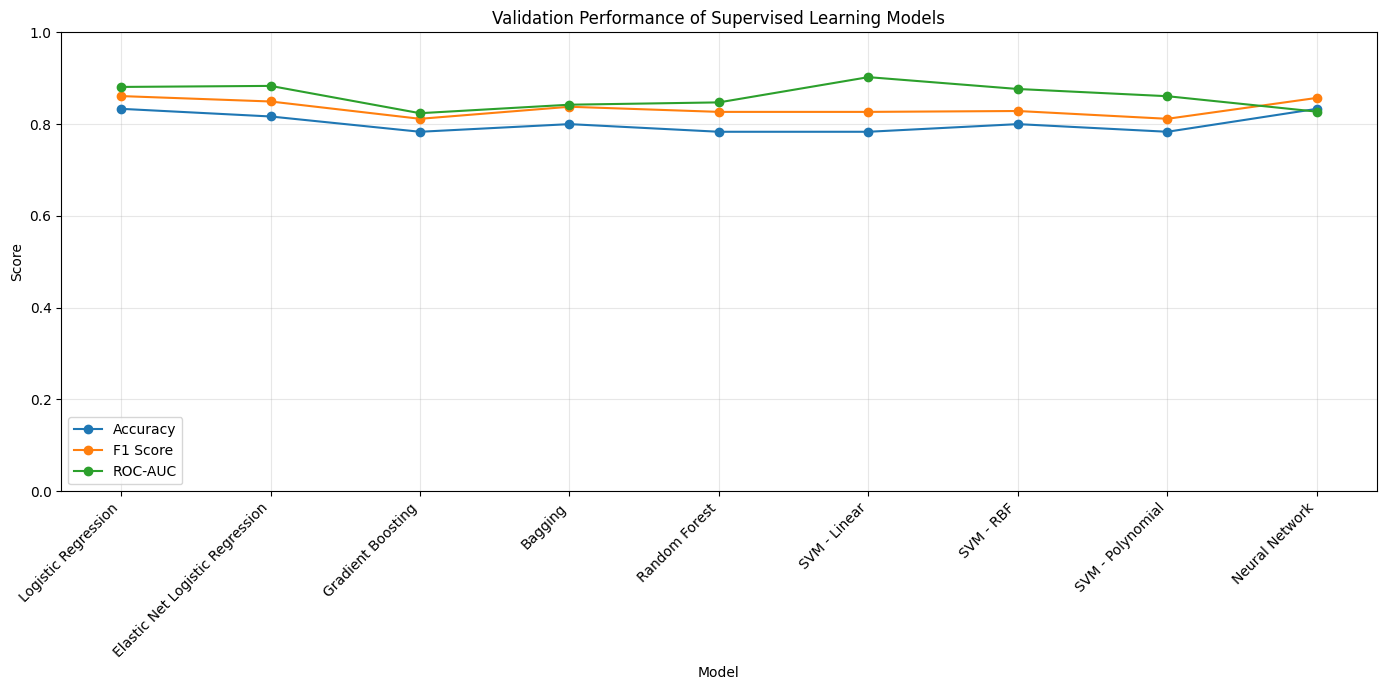

In [26]:
# Plot validation performance of all models

metrics_to_plot = ['Accuracy', 'F1 Score', 'ROC-AUC']

plt.figure(figsize=(14, 7))

x = range(len(results_df))

for metric in metrics_to_plot:
    plt.plot(
        x,
        results_df[metric],
        marker='o',
        label=metric
    )

plt.xticks(x, results_df['Model'], rotation=45, ha='right')
plt.ylabel('Score')
plt.xlabel('Model')
plt.title('Validation Performance of Supervised Learning Models')
plt.ylim(0, 1)
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## Hyperparameter Tuning

Selected models are tuned using GridSearchCV to identify suitable hyperparameters and improve validation performance.

In [29]:
# Train / Validation / Test Split
from sklearn.model_selection import train_test_split

# Separate features and target
X = df.drop('output', axis=1)
y = df['output']

# First split: 60% training, 40% temporary
x_train, x_temp, y_train, y_temp = train_test_split(
    X,
    y,
    test_size=0.40,
    stratify=y,
    random_state=42
)

# Second split: temporary into validation and test
x_val, x_test, y_val, y_test = train_test_split(
    x_temp,
    y_temp,
    test_size=0.50,
    stratify=y_temp,
    random_state=42
)

print("Training set:", x_train.shape, y_train.shape)
print("Validation set:", x_val.shape, y_val.shape)
print("Test set:", x_test.shape, y_test.shape)

Training set: (181, 13) (181,)
Validation set: (60, 13) (60,)
Test set: (61, 13) (61,)


In [30]:
# Preprocess the data

x_train_processed = preprocessor.fit_transform(x_train)
x_val_processed = preprocessor.transform(x_val)
x_test_processed = preprocessor.transform(x_test)

print("Processed training shape:", x_train_processed.shape)
print("Processed validation shape:", x_val_processed.shape)
print("Processed test shape:", x_test_processed.shape)

Processed training shape: (181, 30)
Processed validation shape: (60, 30)
Processed test shape: (61, 30)


In [31]:
from sklearn.model_selection import GridSearchCV
from sklearn.ensemble import RandomForestClassifier

rf_grid = {
    'n_estimators': [100, 200],
    'max_depth': [None, 5, 10],
    'min_samples_split': [2, 5]
}

rf_search = GridSearchCV(
    RandomForestClassifier(random_state=42),
    rf_grid,
    cv=5,
    scoring='roc_auc',
    n_jobs=-1
)

rf_search.fit(x_train_processed, y_train)

print("Best Random Forest Parameters:")
print(rf_search.best_params_)
print("Best CV ROC-AUC:", rf_search.best_score_)

Best Random Forest Parameters:
{'max_depth': 5, 'min_samples_split': 5, 'n_estimators': 100}
Best CV ROC-AUC: 0.9130843653250773


In [32]:
from sklearn.svm import SVC

svm_grid = {
    'C': [0.1, 1, 10],
    'gamma': ['scale', 0.01, 0.1],
    'kernel': ['rbf']
}

svm_search = GridSearchCV(
    SVC(probability=True, random_state=42),
    svm_grid,
    cv=5,
    scoring='roc_auc',
    n_jobs=-1
)

svm_search.fit(x_train_processed, y_train)

print("Best SVM Parameters:")
print(svm_search.best_params_)
print("Best CV ROC-AUC:", svm_search.best_score_)

Best SVM Parameters:
{'C': 1, 'gamma': 0.01, 'kernel': 'rbf'}
Best CV ROC-AUC: 0.9202089783281734


In [33]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

# Random Forest
rf_tuned = rf_search.best_estimator_
rf_pred = rf_tuned.predict(x_val_processed)
rf_prob = rf_tuned.predict_proba(x_val_processed)[:, 1]

print("Tuned Random Forest")
print("Accuracy:", accuracy_score(y_val, rf_pred))
print("Precision:", precision_score(y_val, rf_pred))
print("Recall:", recall_score(y_val, rf_pred))
print("F1 Score:", f1_score(y_val, rf_pred))
print("ROC-AUC:", roc_auc_score(y_val, rf_prob))

# SVM
svm_tuned = svm_search.best_estimator_
svm_pred = svm_tuned.predict(x_val_processed)
svm_prob = svm_tuned.predict_proba(x_val_processed)[:, 1]

print("\nTuned SVM")
print("Accuracy:", accuracy_score(y_val, svm_pred))
print("Precision:", precision_score(y_val, svm_pred))
print("Recall:", recall_score(y_val, svm_pred))
print("F1 Score:", f1_score(y_val, svm_pred))
print("ROC-AUC:", roc_auc_score(y_val, svm_prob))

Tuned Random Forest
Accuracy: 0.7833333333333333
Precision: 0.7380952380952381
Recall: 0.9393939393939394
F1 Score: 0.8266666666666667
ROC-AUC: 0.8428731762065096

Tuned SVM
Accuracy: 0.7833333333333333
Precision: 0.7380952380952381
Recall: 0.9393939393939394
F1 Score: 0.8266666666666667
ROC-AUC: 0.8608305274971941


In [34]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

# Test evaluation for tuned Random Forest
rf_test_pred = rf_tuned.predict(x_test_processed)
rf_test_prob = rf_tuned.predict_proba(x_test_processed)[:, 1]

print("===== TUNED RANDOM FOREST - TEST RESULTS =====")
print("Accuracy:", accuracy_score(y_test, rf_test_pred))
print("Precision:", precision_score(y_test, rf_test_pred))
print("Recall:", recall_score(y_test, rf_test_pred))
print("F1 Score:", f1_score(y_test, rf_test_pred))
print("ROC-AUC:", roc_auc_score(y_test, rf_test_prob))


# Test evaluation for tuned SVM
svm_test_pred = svm_tuned.predict(x_test_processed)
svm_test_prob = svm_tuned.predict_proba(x_test_processed)[:, 1]

print("\n===== TUNED SVM - TEST RESULTS =====")
print("Accuracy:", accuracy_score(y_test, svm_test_pred))
print("Precision:", precision_score(y_test, svm_test_pred))
print("Recall:", recall_score(y_test, svm_test_pred))
print("F1 Score:", f1_score(y_test, svm_test_pred))
print("ROC-AUC:", roc_auc_score(y_test, svm_test_prob))

===== TUNED RANDOM FOREST - TEST RESULTS =====
Accuracy: 0.7868852459016393
Precision: 0.7777777777777778
Recall: 0.8484848484848485
F1 Score: 0.8115942028985508
ROC-AUC: 0.9166666666666667

===== TUNED SVM - TEST RESULTS =====
Accuracy: 0.8360655737704918
Precision: 0.8108108108108109
Recall: 0.9090909090909091
F1 Score: 0.8571428571428571
ROC-AUC: 0.9350649350649352


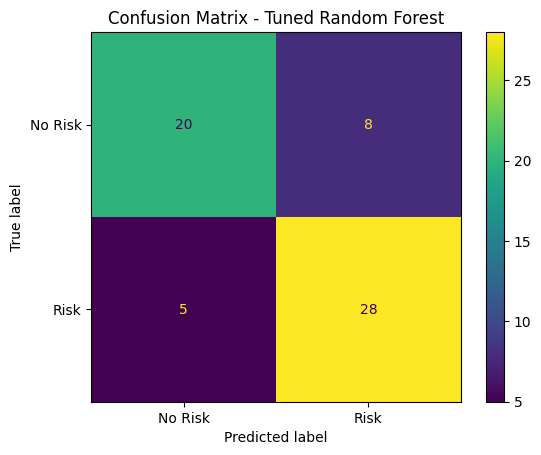

In [35]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Random Forest confusion matrix
cm_rf = confusion_matrix(y_test, rf_test_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_rf,
    display_labels=['No Risk', 'Risk']
)

disp.plot()
plt.title("Confusion Matrix - Tuned Random Forest")
plt.show()

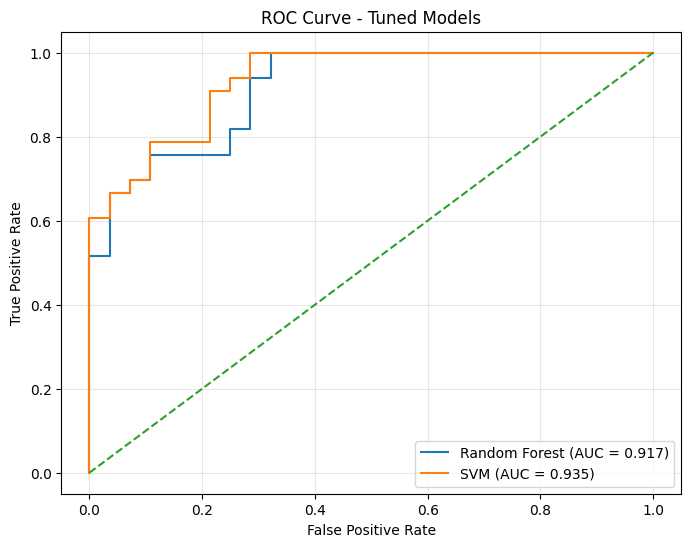

In [36]:
from sklearn.metrics import roc_curve

rf_fpr, rf_tpr, _ = roc_curve(y_test, rf_test_prob)
svm_fpr, svm_tpr, _ = roc_curve(y_test, svm_test_prob)

plt.figure(figsize=(8, 6))

plt.plot(
    rf_fpr,
    rf_tpr,
    label=f"Random Forest (AUC = {roc_auc_score(y_test, rf_test_prob):.3f})"
)

plt.plot(
    svm_fpr,
    svm_tpr,
    label=f"SVM (AUC = {roc_auc_score(y_test, svm_test_prob):.3f})"
)

plt.plot([0, 1], [0, 1], linestyle='--')

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Tuned Models")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [37]:
# Final test performance comparison

final_results = pd.DataFrame({
    'Model': ['Tuned Random Forest', 'Tuned SVM'],
    'Accuracy': [
        accuracy_score(y_test, rf_test_pred),
        accuracy_score(y_test, svm_test_pred)
    ],
    'Precision': [
        precision_score(y_test, rf_test_pred),
        precision_score(y_test, svm_test_pred)
    ],
    'Recall': [
        recall_score(y_test, rf_test_pred),
        recall_score(y_test, svm_test_pred)
    ],
    'F1 Score': [
        f1_score(y_test, rf_test_pred),
        f1_score(y_test, svm_test_pred)
    ],
    'ROC-AUC': [
        roc_auc_score(y_test, rf_test_prob),
        roc_auc_score(y_test, svm_test_prob)
    ]
})

display(final_results.round(4))

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Tuned Random Forest,0.7869,0.7778,0.8485,0.8116,0.9167
1,Tuned SVM,0.8361,0.8108,0.9091,0.8571,0.9351


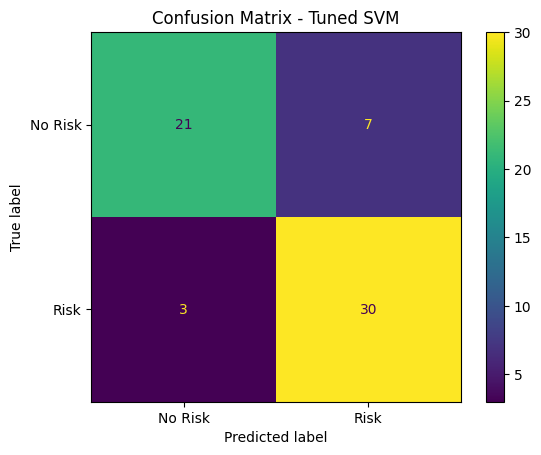

In [38]:
from sklearn.metrics import ConfusionMatrixDisplay

cm_svm = confusion_matrix(y_test, svm_test_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_svm,
    display_labels=['No Risk', 'Risk']
)

disp.plot()
plt.title("Confusion Matrix - Tuned SVM")
plt.show()

In [39]:
import joblib

joblib.dump(svm_tuned, 'heart_attack_prediction_model.pkl')

print("Final SVM model saved successfully.")

Final SVM model saved successfully.
